# Section:1 ->Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

# Section 2: Load & Understand Dataset

In [2]:
import os
full = os.path.join("data", "creditcard.csv")
sample = os.path.join("data", "creditcard_sample.csv")
df = pd.read_csv(full if os.path.exists(full) else sample)
print(f"Dataset Shape   : {df.shape}")
print(f"Total Rows      : {df.shape[0]}")
print(f"Total Columns   : {df.shape[1]}")
df.head()

Dataset Shape   : (284807, 31)
Total Rows      : 284807
Total Columns   : 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# ── Data types overview ───────────────────────────────────────────
print("Column Data Types:")
print(df.dtypes.value_counts())
print(f"\nNumerical columns  : {df.select_dtypes(include=[np.number]).shape[1]}")
print(f"Categorical columns: {df.select_dtypes(include=['object']).shape[1]}")

Column Data Types:
float64    30
int64       1
Name: count, dtype: int64

Numerical columns  : 31
Categorical columns: 0


In [4]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [5]:
print(df.info())
print(df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [7]:
df.duplicated().sum()

np.int64(1081)

In [8]:
# ── Target distribution ───────────────────────────────────────────
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100
print(class_counts)
print(f"\nFraud rate: {class_pct[1]:.4f}%  (legit: {class_pct[0]:.4f}%)")
print('Fraud ratio:', df['Class'].mean())



Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.1727%  (legit: 99.8273%)
Fraud ratio: 0.001727485630620034


# Section 3: Exploratory Data Analysis (EDA)

In [9]:
missing = df.isnull().sum()
print(f"Total columns with missing values: {(missing > 0).sum()}")


Total columns with missing values: 0


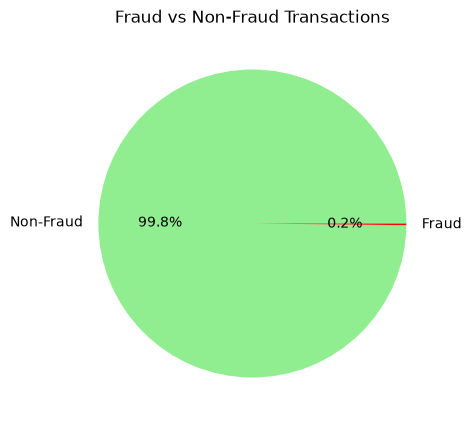

In [10]:
# Pie chart
plt.figure(figsize=(5,5))
plt.pie(df['Class'].value_counts().values, labels=['Non-Fraud', 'Fraud'], autopct='%1.1f%%', colors=['lightgreen', 'red'])
plt.title('Fraud vs Non-Fraud Transactions')
plt.show()

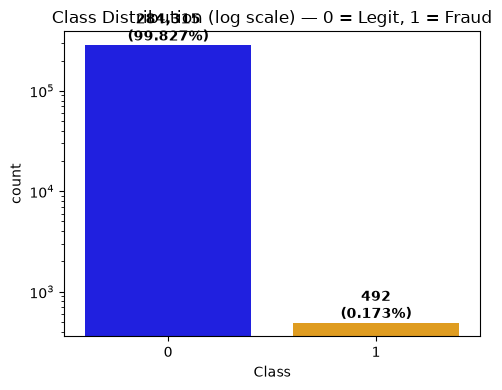

In [11]:
# ── Class imbalance (log scale — the minority class is otherwise invisible) ──
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='Class', hue='Class', palette=['blue', 'orange'], legend=False, ax=ax)
ax.set_yscale('log')
ax.set_title('Class Distribution (log scale) — 0 = Legit, 1 = Fraud')
for i, v in enumerate(class_counts.reindex([0, 1])):
    ax.text(i, v, f"{v:,}\n({class_pct.reindex([0,1]).iloc[i]:.3f}%)", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


The dataset is **extremely** imbalanced (~0.17% fraud) — far more skewed than typical churn
data. This drives every downstream choice: `class_weight`/`scale_pos_weight` in the models,
PR-AUC (not accuracy) as the headline metric, and a threshold chosen from the precision-recall
curve rather than the default 0.5.

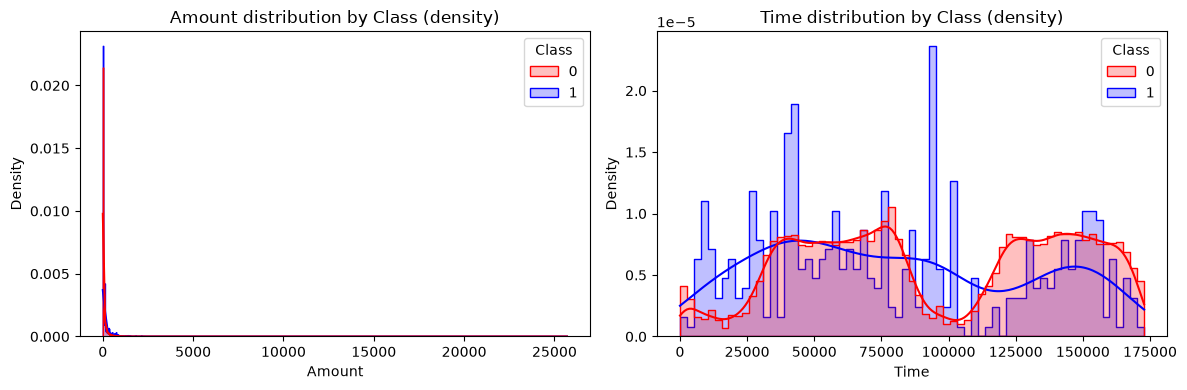

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['Amount', 'Time']):
    sns.histplot(data=df, x=col, hue='Class', kde=True, element='step', ax=ax,
                 palette=['red', 'blue'], common_norm=False, stat='density')
    ax.set_title(f'{col} distribution by Class (density)')
plt.tight_layout()
plt.show()

**Amount:** fraudulent transactions skew toward smaller amounts on average, but with a long
  tail of high-value fraud — worth capping/robust-scaling rather than standard-scaling.
- **Time:** `Time` is seconds since the first transaction (~2 days of data). Look for the two daily
  cycles in transaction volume; fraud doesn't cleanly follow the same day/night pattern as
  legitimate traffic.

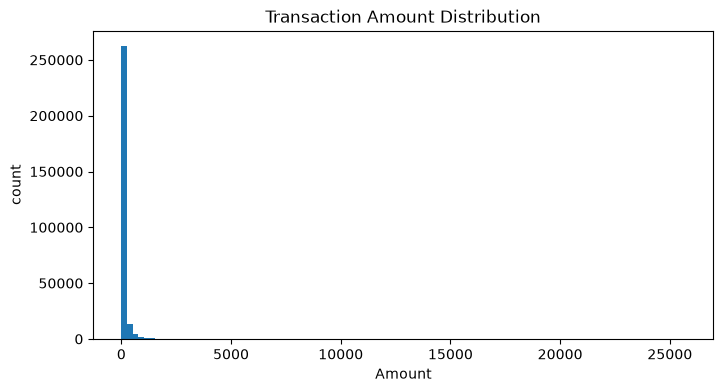

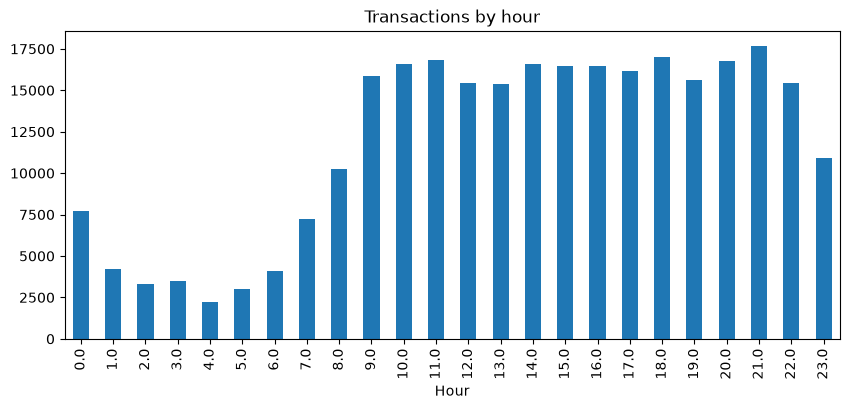

In [13]:
# Amount distribution
plt.figure(figsize=(8,4))
plt.hist(df['Amount'], bins=100)
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount')
plt.ylabel('count')
plt.show()

# Time-based overview (the dataset's Time column in seconds since first transaction)
if 'Time' in df.columns:
    df['Hour'] = (df['Time'] // 3600) % 24
    plt.figure(figsize=(10,4))
    df.groupby('Hour').size().plot(kind='bar')
    plt.title('Transactions by hour')
    plt.show()


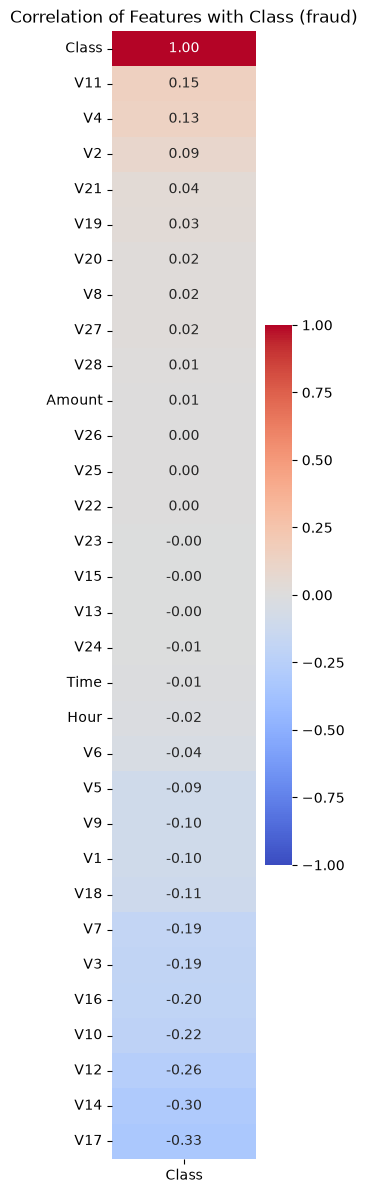

Top positive correlations:
 Class    1.000000
V11      0.154876
V4       0.133447
V2       0.091289
V21      0.040413
V19      0.034783
Name: Class, dtype: float64

Top negative correlations:
 V3    -0.192961
V16   -0.196539
V10   -0.216883
V12   -0.260593
V14   -0.302544
V17   -0.326481
Name: Class, dtype: float64


In [14]:
# Correlation of all numeric features (V1-V28, Amount, Time) with Class
corr_matrix = df.corr(numeric_only=True)
class_corr = corr_matrix[['Class']].sort_values(by='Class', ascending=False)

plt.figure(figsize=(4.5, 12))
sns.heatmap(class_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation of Features with Class (fraud)')
plt.subplots_adjust(left=0.55, right=0.95, top=0.97, bottom=0.03)
plt.show()

print("Top positive correlations:\n", class_corr['Class'].head(6))
print("\nTop negative correlations:\n", class_corr['Class'].tail(6))


Because `V1`–`V28` are PCA components, they're constructed to be (close to) mutually
uncorrelated — that's the point of PCA. So  we don't expect a
multicollinearity problem among them, and we skip a full VIF sweep over all 30 features. We only
sanity-check VIF for the engineered `Amount`/`Time` features below, after scaling.

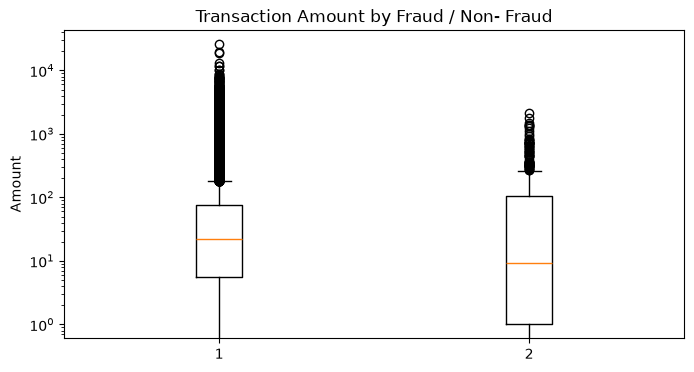

In [ ]:
# Fraud vs Non-Fraud Amount
plt.figure(figsize=(8,4))
amount_nonfraud = df[df['Class']==0]['Amount']
amount_fraud = df[df['Class']==1]['Amount']
plt.boxplot([amount_nonfraud, amount_fraud],labels=['Non-Fraud', 'Fraud'])
plt.yscale('log')    # because amounts are skewed
plt.ylabel('Amount')
plt.title('Transaction Amount by Fraud / Non- Fraud')
plt.show()

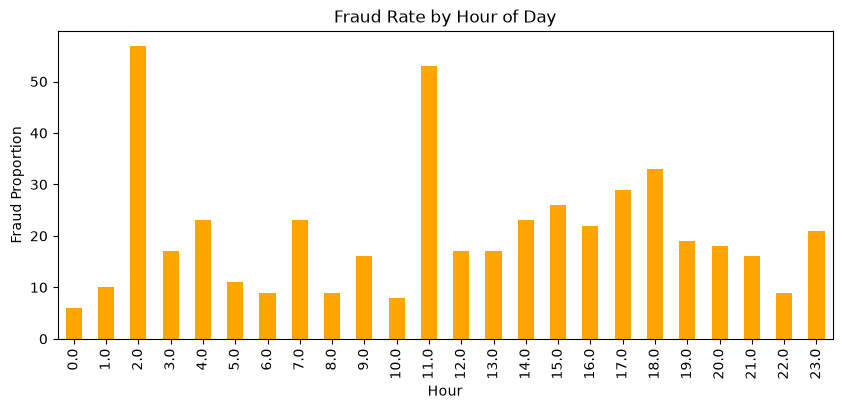

In [17]:
#Hourly fraud
hourly = df.groupby('Hour')['Class'].sum()
plt.figure(figsize=(10,4))
hourly.plot(kind='bar', color='orange')
plt.ylabel('Fraud Proportion')
plt.title('Fraud Rate by Hour of Day')
plt.show()

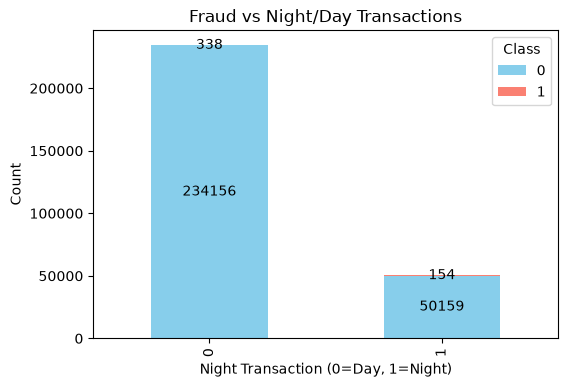

In [18]:
# Night vs Day Fraud
df['is_night'] = df['Hour'].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int)

night_fraud = df.groupby(['is_night','Class']).size().unstack(fill_value=0)
ax = night_fraud.plot(kind='bar',stacked=True,figsize=(6,4),color=['skyblue','salmon'])
plt.xlabel('Night Transaction (0=Day, 1=Night)')
plt.ylabel('Count')
plt.title('Fraud vs Night/Day Transactions')
for container in ax.containers:
    ax.bar_label(container, label_type='center', fmt='%d')
plt.show()

# Section 4: Feature Engineering

In [19]:
# V1-V28 are already PCA-transformed / scaled, so only Amount and Time need treatment:
#   Amount -> log1p (fixes the long right tail) -> RobustScaler (median/IQR, outlier-resistant)
#   Time   -> RobustScaler


def build_preprocessor():
    amount_pipe = Pipeline([
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', RobustScaler()),
    ])
    prep = ColumnTransformer(
        [('amount', amount_pipe, ['Amount']),
         ('time', RobustScaler(), ['Time'])],
        remainder='passthrough',            # V1-V28 pass through unchanged
        verbose_feature_names_out=False,    # keep original column names
    )
    return prep.set_output(transform='pandas')

def make_pipeline(clf):
    """Preprocessing + classifier as ONE estimator (fresh preprocessor each call)."""
    return Pipeline([('prep', build_preprocessor()), ('clf', clf)])

print(f"Missing values: {df.isna().sum().sum()}")
print(df[['Amount', 'Time']].describe().T)   # raw columns are kept in df on purpose

Missing values: 0
           count          mean           std  min      25%      50%  \
Amount  284807.0     88.349619    250.120109  0.0      5.6     22.0   
Time    284807.0  94813.859575  47488.145955  0.0  54201.5  84692.0   

               75%        max  
Amount      77.165   25691.16  
Time    139320.500  172792.00  


# Section 5: Multicollinearity Check (engineered features only)

In [20]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Diagnostic only (not used for modeling): transform a copy to see the engineered features
X_vif = build_preprocessor().fit_transform(df.drop(columns=['Class']))
X_vif = X_vif.replace([np.inf, -np.inf], np.nan).dropna()

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    vif_data = pd.DataFrame({
        'feature': X_vif.columns,
        'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
    }).sort_values(by='VIF', ascending=False)

vif_data.head(10)

,feature,VIF
1,Time,2.545011
30,Hour,1.876930
0,Amount,1.648658
4,V3,1.431345
3,V2,1.338159
31,is_night,1.301093
13,V12,1.298987
6,V5,1.229755
16,V15,1.171984
12,V11,1.140934


# Section 6: Machine Learning

In [21]:
X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=41, stratify=y
)

print(f"Train fraud rate: {y_train.mean()*100:.4f}%   Test fraud rate: {y_test.mean()*100:.4f}%")


Train fraud rate: 0.1729%   Test fraud rate: 0.1720%


**Evaluation helper.** `evaluate_model` prints the classification report, average precision,
ROC-AUC and confusion matrix, optionally draws the PR curve, and returns the scores. It is used
for every model below. Because the models are pipelines, it is called on raw `X_test`; the
pipeline scales it internally.

In [22]:
# ── Evaluation utility (works on plain models AND on pipelines) ──────────────
def evaluate_model(model, X_test, y_test, thresh=0.5, show_pr_curve=True):
    # obtain probabilities or scores
    if hasattr(model, 'predict_proba'):
        y_scores = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        s = model.decision_function(X_test)
        y_scores = (s - s.min()) / (s.max() - s.min() + 1e-9)
    else:
        y_scores = model.predict(X_test)
    y_pred = (y_scores >= thresh).astype(int)
    print('Classification report (threshold={}):'.format(thresh))
    print(classification_report(y_test, y_pred, digits=4))
    ap = average_precision_score(y_test, y_scores)
    roc = roc_auc_score(y_test, y_scores)
    cm = confusion_matrix(y_test, y_pred)
    print('Average precision (AUPRC):', ap)
    print('ROC AUC:', roc)
    print('Confusion matrix:\n', cm)
    if show_pr_curve:
        precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
        plt.figure(figsize=(6, 4))
        plt.plot(recall, precision)
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title(f'PR curve (AP={ap:.4f})')
        plt.show()
    return {'ap': ap, 'roc': roc, 'scores': y_scores, 'y_pred': y_pred, 'cm': cm}

**Threshold helper.** `evaluate_model` scores a model at one threshold; `threshold_analysis`
shows precision/recall/F1 across many thresholds so you can see where a better operating point is.

In [23]:
def threshold_analysis(y_true, proba, title='', thresholds=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7), plot=True):
    """Precision / recall / F1 of the fraud class across thresholds (helps choose an operating point)."""
    if plot:
        prec, rec, thr = precision_recall_curve(y_true, proba)
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(thr, prec[:-1], label='Precision')
        ax.plot(thr, rec[:-1], label='Recall')
        ax.set_xlabel('Threshold')
        ax.set_title(f'{title}: Precision/Recall vs Threshold')
        ax.legend()
        plt.tight_layout()
        plt.show()

    print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
    for t in thresholds:
        preds = (proba >= t).astype(int)
        print(f"{t:<8}"
              f"{precision_score(y_true, preds, pos_label=1, zero_division=0):<8.3f}"
              f"{recall_score(y_true, preds, pos_label=1, zero_division=0):<8.3f}"
              f"{f1_score(y_true, preds, pos_label=1, zero_division=0):<8.3f}")

### Random Forest (baseline)

Classification report (threshold=0.5):
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9268    0.7755    0.8444        98

    accuracy                         0.9995     56962
   macro avg     0.9632    0.8877    0.9221     56962
weighted avg     0.9995    0.9995    0.9995     56962

Average precision (AUPRC): 0.8128611665455924
ROC AUC: 0.9642439928278572
Confusion matrix:
 [[56858     6]
 [   22    76]]


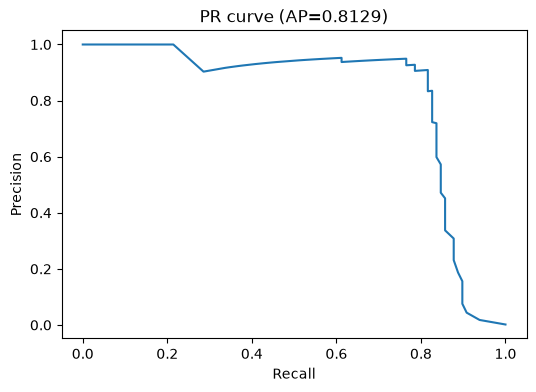

In [24]:
rf = make_pipeline(RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
))
rf.fit(X_train, y_train)

res_rf = evaluate_model(rf, X_test, y_test, thresh=0.5)
proba = res_rf['scores']        # reused below for the threshold analysis


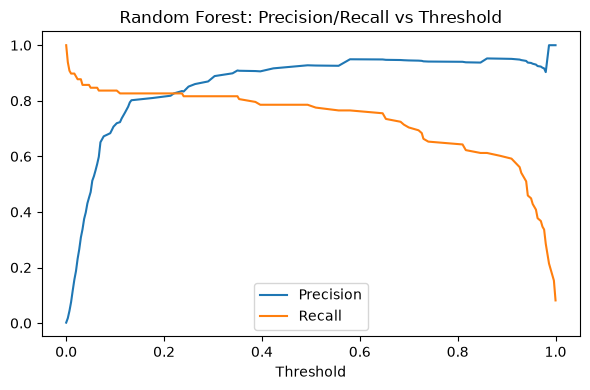

Thresh  Prec_1  Rec_1   F1_1    
0.1     0.713   0.837   0.770   
0.2     0.818   0.827   0.822   
0.3     0.889   0.816   0.851   
0.4     0.917   0.786   0.846   
0.5     0.927   0.776   0.844   
0.6     0.949   0.755   0.841   
0.7     0.945   0.704   0.807   


In [25]:
# Precision/recall across thresholds, instead of guessing one up front
threshold_analysis(y_test, proba, title='Random Forest')

###  LightGBM

Training time: 3.72 seconds
Prediction time: 0.2298 seconds
Classification report (threshold=0.5):
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56864
           1     0.9000    0.8265    0.8617        98

    accuracy                         0.9995     56962
   macro avg     0.9499    0.9132    0.9307     56962
weighted avg     0.9995    0.9995    0.9995     56962

Average precision (AUPRC): 0.8242181639604664
ROC AUC: 0.9777408395828787
Confusion matrix:
 [[56855     9]
 [   17    81]]


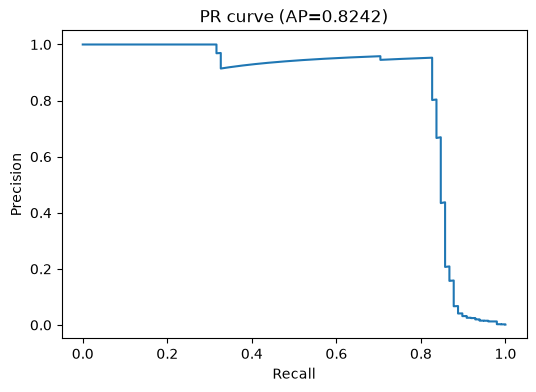

In [26]:
import time

lgbm = make_pipeline(LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
))

start_train = time.time()
lgbm.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"Training time: {train_time:.2f} seconds")

start_pred = time.time()
proba = lgbm.predict_proba(X_test)[:, 1]
pred_time = time.time() - start_pred
print(f"Prediction time: {pred_time:.4f} seconds")

res_lgbm = evaluate_model(lgbm, X_test, y_test, thresh=0.5, show_pr_curve=True)


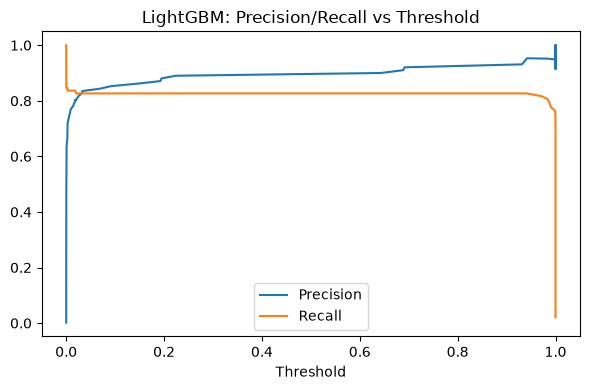

Thresh  Prec_1  Rec_1   F1_1    
0.1     0.862   0.827   0.844   
0.2     0.890   0.827   0.857   
0.3     0.900   0.827   0.862   
0.4     0.900   0.827   0.862   
0.5     0.900   0.827   0.862   
0.6     0.900   0.827   0.862   
0.7     0.931   0.827   0.876   


In [27]:
threshold_analysis(y_test, res_lgbm['scores'], title='LightGBM', plot=True)

###  XGBoost

Training time: 7.12 seconds
Prediction time: 0.0887 seconds
Classification report (threshold=0.5):
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56864
           1     0.8889    0.8163    0.8511        98

    accuracy                         0.9995     56962
   macro avg     0.9443    0.9081    0.9254     56962
weighted avg     0.9995    0.9995    0.9995     56962

Average precision (AUPRC): 0.8251240790770352
ROC AUC: 0.9833003808585898
Confusion matrix:
 [[56854    10]
 [   18    80]]


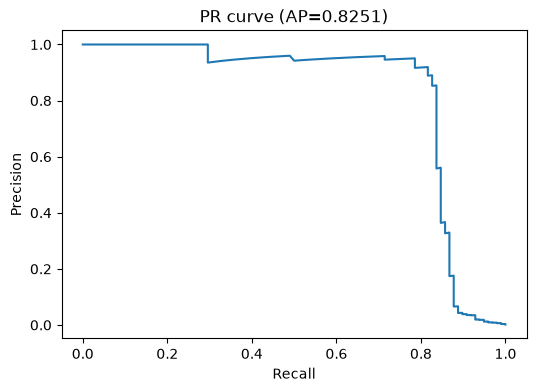

In [28]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = make_pipeline(XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    eval_metric='aucpr'   # PR-AUC-aligned eval metric, more appropriate than logloss here
))

start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"Training time: {train_time:.2f} seconds")

start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1]
pred_time = time.time() - start_pred
print(f"Prediction time: {pred_time:.4f} seconds")

res_xgb = evaluate_model(xgb, X_test, y_test, thresh=0.5, show_pr_curve=True)


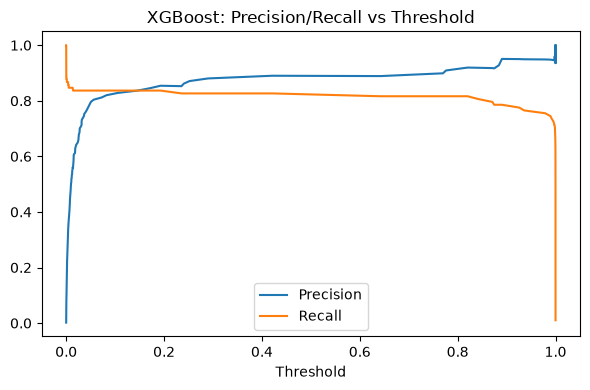

Thresh  Prec_1  Rec_1   F1_1    
0.1     0.828   0.837   0.832   
0.2     0.853   0.827   0.839   
0.3     0.890   0.827   0.857   
0.4     0.890   0.827   0.857   
0.5     0.889   0.816   0.851   
0.6     0.889   0.816   0.851   
0.7     0.899   0.816   0.856   


In [29]:
threshold_analysis(y_test, res_xgb['scores'], title='XGBoost', plot=True)

               AP (PR-AUC)  ROC-AUC
XGBoost             0.8251   0.9833
LightGBM            0.8242   0.9777
Random Forest       0.8129   0.9642


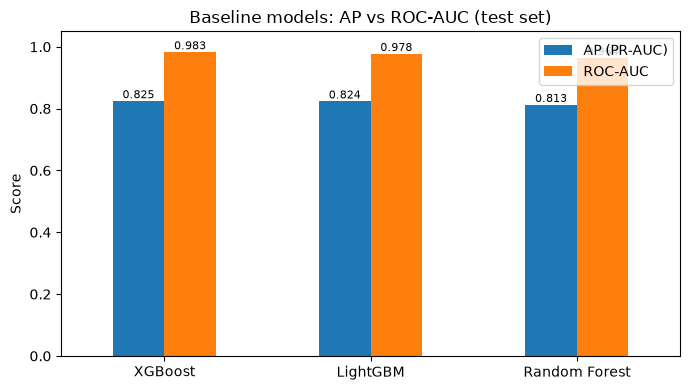

In [30]:
# ── Compare baseline models: AP (PR-AUC) and ROC-AUC ──────────────────────────
results = {
    'Random Forest': res_rf,
    'LightGBM':      res_lgbm,
    'XGBoost':       res_xgb,
}
comparison = (pd.DataFrame({name: {'AP (PR-AUC)': r['ap'], 'ROC-AUC': r['roc']}
                            for name, r in results.items()})
                .T.sort_values('AP (PR-AUC)', ascending=False))
print(comparison.round(4))

ax = comparison.plot(kind='bar', figsize=(7, 4), rot=0, ylim=(0, 1.05))
ax.set_title('Baseline models: AP vs ROC-AUC (test set)')
ax.set_ylabel('Score')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

# Section 7: Hyperparameter Tuning (Optuna) & Experiment Tracking (MLflow)

We optimize **mean cross-validated average precision (PR-AUC)** with `StratifiedKFold`, rather
than a single train/test recall score. With only ~0.17% positives, a single split's recall is
noisy — one or two flipped predictions can swing it a lot — so cross-validation gives a more
reliable objective for the search.

In [31]:
import optuna

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": (y_train == 0).sum() / (y_train == 1).sum(),
        "eval_metric": "aucpr",
    }

    # Whole pipeline is cross-validated: scalers are refit on each training fold (no leakage)
    model = make_pipeline(XGBClassifier(**params))
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='average_precision', n_jobs=-1)
    return scores.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

print("Best Params:", study.best_params)
print("Best CV Average Precision:", study.best_value)


[I 2026-10-14 14:39:25,120] A new study created in memory with name: no-name-7726d3b6-2833-4ab9-bf05-3dfdc510dcb4
[I 2026-10-14 14:39:48,435] Trial 0 finished with value: 0.8435226472738389 and parameters: {'n_estimators': 492, 'learning_rate': 0.036423867348113745, 'max_depth': 10, 'subsample': 0.9429135753597879, 'colsample_bytree': 0.7510676102034443, 'min_child_weight': 4, 'gamma': 4.258441505204408, 'reg_alpha': 4.997720050812632, 'reg_lambda': 4.271049731126077}. Best is trial 0 with value: 0.8435226472738389.
[I 2026-10-14 14:40:20,897] Trial 1 finished with value: 0.8603630620407273 and parameters: {'n_estimators': 722, 'learning_rate': 0.046777513576995396, 'max_depth': 6, 'subsample': 0.5471834158310893, 'colsample_bytree': 0.9936110470059911, 'min_child_weight': 3, 'gamma': 2.8727265773042623, 'reg_alpha': 4.139518937081028, 'reg_lambda': 0.9003474828477398}. Best is trial 1 with value: 0.8603630620407273.
[I 2026-10-14 14:40:45,456] Trial 2 finished with value: 0.8578003551

Best Params: {'n_estimators': 741, 'learning_rate': 0.07202018682432022, 'max_depth': 6, 'subsample': 0.5177910128998944, 'colsample_bytree': 0.6918867979179337, 'min_child_weight': 5, 'gamma': 2.812030045814842, 'reg_alpha': 1.4292758828322698, 'reg_lambda': 3.9032635840494962}
Best CV Average Precision: 0.86493693099046


Training time: 5.62 seconds
Prediction time: 0.0693 seconds
Threshold maximizing F1 on cross-validated train predictions: 0.884
Classification report (threshold=0.8841086626052856):
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9186    0.8061    0.8587        98

    accuracy                         0.9995     56962
   macro avg     0.9591    0.9030    0.9292     56962
weighted avg     0.9995    0.9995    0.9995     56962

Average precision (AUPRC): 0.8244115582093339
ROC AUC: 0.9839588621042115
Confusion matrix:
 [[56857     7]
 [   19    79]]


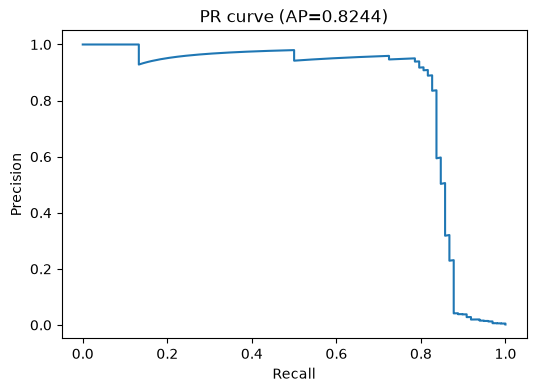

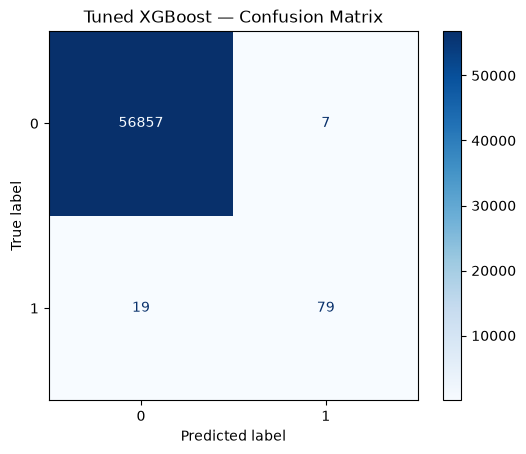

In [32]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

best_params = study.best_params
best_params.update({
    "random_state": 42,
    "n_jobs": -1,
    "scale_pos_weight": scale_pos_weight,
    "eval_metric": "aucpr",
})

xgb = make_pipeline(XGBClassifier(**best_params))   # tuned model + preprocessing as one object

start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"Training time: {train_time:.2f} seconds")

start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1]
pred_time = time.time() - start_pred
print(f"Prediction time: {pred_time:.4f} seconds")

# Pick the operating threshold from CROSS-VALIDATED predictions on the TRAINING set,
# so the test set is never used to tune anything and the final test metrics stay honest.
cv_proba = cross_val_predict(xgb, X_train, y_train, cv=skf,
                             method='predict_proba', n_jobs=-1)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, cv_proba)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_idx = np.nanargmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]
print(f"Threshold maximizing F1 on cross-validated train predictions: {best_threshold:.3f}")

res_tuned = evaluate_model(xgb, X_test, y_test, thresh=best_threshold)
y_pred = res_tuned['y_pred']

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Tuned XGBoost — Confusion Matrix')
plt.show()


In [33]:
# ── Final comparison: baselines vs tuned XGBoost ──────────────────────────────
results['XGBoost (tuned)'] = res_tuned
final_cmp = (pd.DataFrame({name: {'AP (PR-AUC)': r['ap'], 'ROC-AUC': r['roc']}
                           for name, r in results.items()})
               .T.sort_values('AP (PR-AUC)', ascending=False))
print(final_cmp.round(4))

                 AP (PR-AUC)  ROC-AUC
XGBoost               0.8251   0.9833
XGBoost (tuned)       0.8244   0.9840
LightGBM              0.8242   0.9777
Random Forest         0.8129   0.9642
